# CrowdPulse: Multi-Agent Crowd Density Estimation and Coordinated Alerting System
**Course:** INT395 - Supervised Learning | **Problem Statement ID:** #20  
**Dataset:** ShanghaiTech Crowd Counting Dataset (Part B)  
**Authors:** Student Research Group (Reg. Nos: 12201941, 12202052, 12203114)  
**Target Platform:** Edge-Compatible Surveillance & Real-Time Autonomous Coordination  

---

## Executive Summary & Course Outcome (CO) Alignment
Public venue safety and industrial facility management require proactive bottleneck detection before stampedes or dangerous crushes occur. While end-to-end deep convolutional networks (e.g., CSRNet, MCNN) achieve low count errors, their gigabyte-scale memory footprints and high computational latency make them impractical for edge-deployed smart surveillance cameras. 

**CrowdPulse** introduces a classical machine learning paradigm:
1. Spatial partitioning of surveillance frames into a $3 \\times 3$ grid (9 zones).
2. Edge-compatible feature extraction combining **Histogram of Oriented Gradients (HOG)**, **Canny Edge Density**, **Local Binary Patterns (LBP)**, and **Pixel Intensity Statistics**.
3. Supervised regression using Scikit-learn ensembles (**Random Forest Regressor** with `StandardScaler`).
4. Operational safety categorization into **3 Risk Tiers** (Green: $<10$, Yellow: $10-24$, Red: $\ge 25$).
5. **SHAP (SHapley Additive exPlanations)** TreeExplainer for transparent, auditable decision making.
6. A decentralized **Multi-Agent Coordination Broker** that flags adjacent high-density zones as critical bottlenecks and issues dynamic crowd rerouting directives.

### Syllabus Mapping:
- **CO1:** Formulate crowd monitoring as a supervised regression task on localized spatial partitions.
- **CO2:** Perform rigorous data preprocessing and feature engineering on ShanghaiTech Part B ground-truth annotations.
- **CO3:** Implement and compare linear, non-linear, and ensemble regression models.
- **CO4:** Apply $k$-fold cross-validation and hyperparameter tuning to prevent overfitting.
- **CO5:** Evaluate models using both continuous metrics ($MAE, RMSE, R^2$) and discrete multi-class safety tiers (Precision, Recall, Macro F1, Confusion Matrix).
- **CO6:** Deliver model interpretability via SHAP and deploy interactive telemetry via Streamlit.


In [1]:
# Cell 1: Environment & Module Setup
import os
import sys
from pathlib import Path

# Set up project root directory
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "CrowdPulse" else Path(".").resolve()
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(str(PROJECT_ROOT))

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio
import scipy.stats as stats
import seaborn as sns
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, classification_report, confusion_matrix
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import shap

# Verify reproducibility
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="muted")
print(f"Working Directory: {PROJECT_ROOT}")
print("All core dependencies successfully imported.")


C:\Users\pudis\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Working Directory: D:\studies\LPU\sem_3\INT395 - Supervised Learning\CrowdPulse
All core dependencies successfully imported.


---
## Section 2: ShanghaiTech Part B Dataset Loading & Ground Truth Parsing

The **ShanghaiTech Part B** dataset contains surveillance camera footage captured on busy urban streets. Each image has a corresponding MATLAB `.mat` ground-truth file containing human head annotations:
$$D(p) = \sum_{i=1}^{N} \delta(p - p_i)$$
where $p_i = (x_i, y_i)$ denotes the exact pixel coordinates of the $i$-th head.

In this section, we parse the `.mat` structure (`image_info[0][0][0][0][0]`) and render a sample surveillance frame with ground-truth coordinates overlaid.


Loading raw image: processed_IMG_1.jpg
Frame Dimensions: Height = 1536 px, Width = 2048 px
Total Ground-Truth Head Count: 233 pedestrians


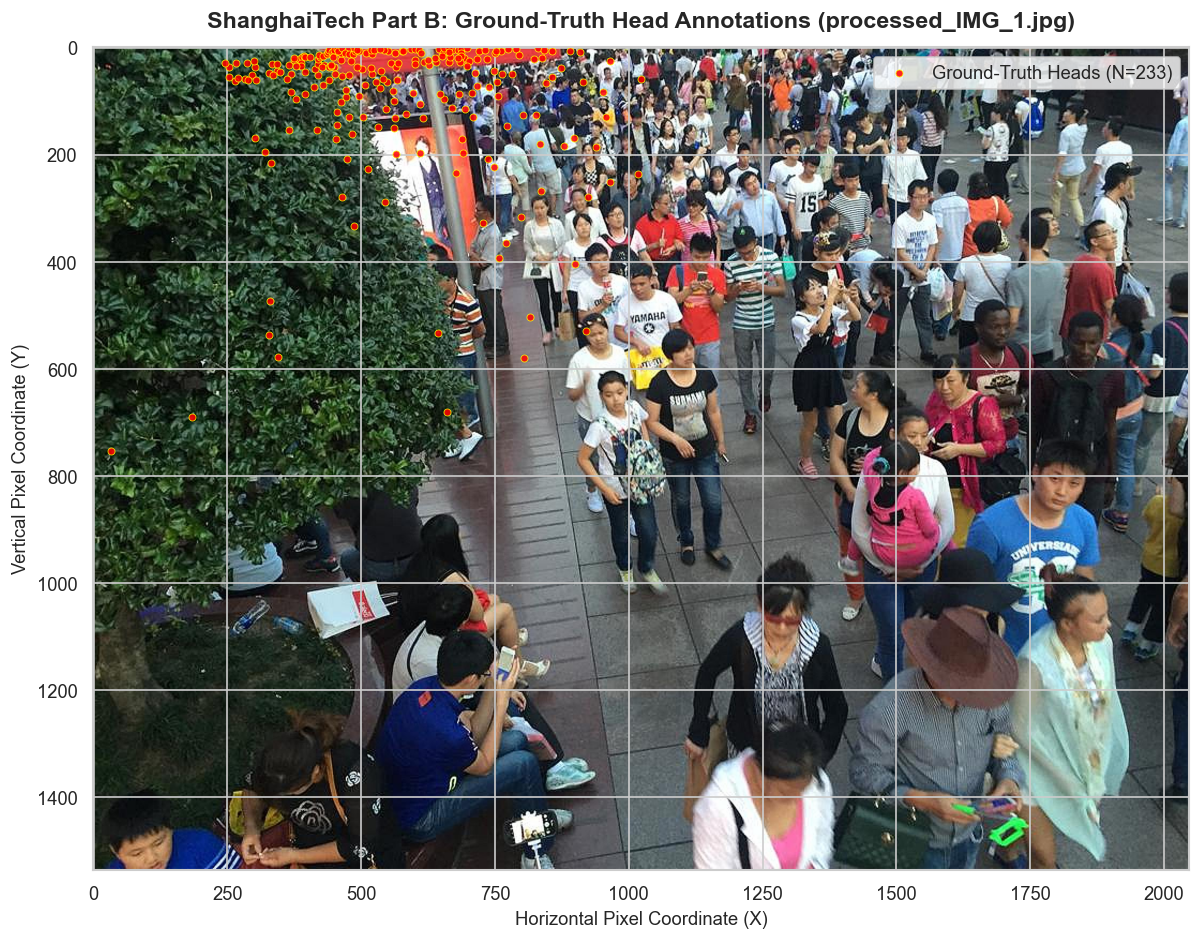

In [2]:
# Cell 2: Ground Truth .mat Parser & Visualization
from src.data_loader import parse_mat_annotations, find_raw_data_dir

raw_dir = find_raw_data_dir()
sample_img_path = raw_dir / "train_data" / "images" / "processed_IMG_1.jpg"
sample_mat_path = raw_dir / "train_data" / "ground-truth" / "GT_IMG_1.mat"

print(f"Loading raw image: {sample_img_path.name}")
img = cv2.imread(str(sample_img_path))
h, w = img.shape[:2]

head_points = parse_mat_annotations(sample_mat_path)
total_heads = len(head_points)
print(f"Frame Dimensions: Height = {h} px, Width = {w} px")
print(f"Total Ground-Truth Head Count: {total_heads} pedestrians")

# Plot surveillance frame with ground-truth head points
fig, ax = plt.subplots(figsize=(12, 8), dpi=120)
ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
ax.scatter(head_points[:, 0], head_points[:, 1], c='red', s=18, edgecolors='yellow', linewidths=0.5, label=f"Ground-Truth Heads (N={total_heads})", alpha=0.85)
ax.set_title(f"ShanghaiTech Part B: Ground-Truth Head Annotations ({sample_img_path.name})", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Horizontal Pixel Coordinate (X)", fontsize=11)
ax.set_ylabel("Vertical Pixel Coordinate (Y)", fontsize=11)
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()


---
## Section 3: Spatial $3 \times 3$ Grid Slicing & Local Ground-Truth Assignment

To avoid calculating head coordinates through dense optical networks, CrowdPulse partitions the entire camera frame into 9 spatial zones ($r \in \{0, 1, 2\}, c \in \{0, 1, 2\}$):
$$r = \min\left(\left\lfloor \frac{y}{H / 3} \right\rfloor, 2\right), \quad c = \min\left(\left\lfloor \frac{x}{W / 3} \right\rfloor, 2\right)$$

Each head $(x_i, y_i)$ maps to an exact zone $Z_{r, c}$, yielding localized ground-truth targets $y_{r, c}$.


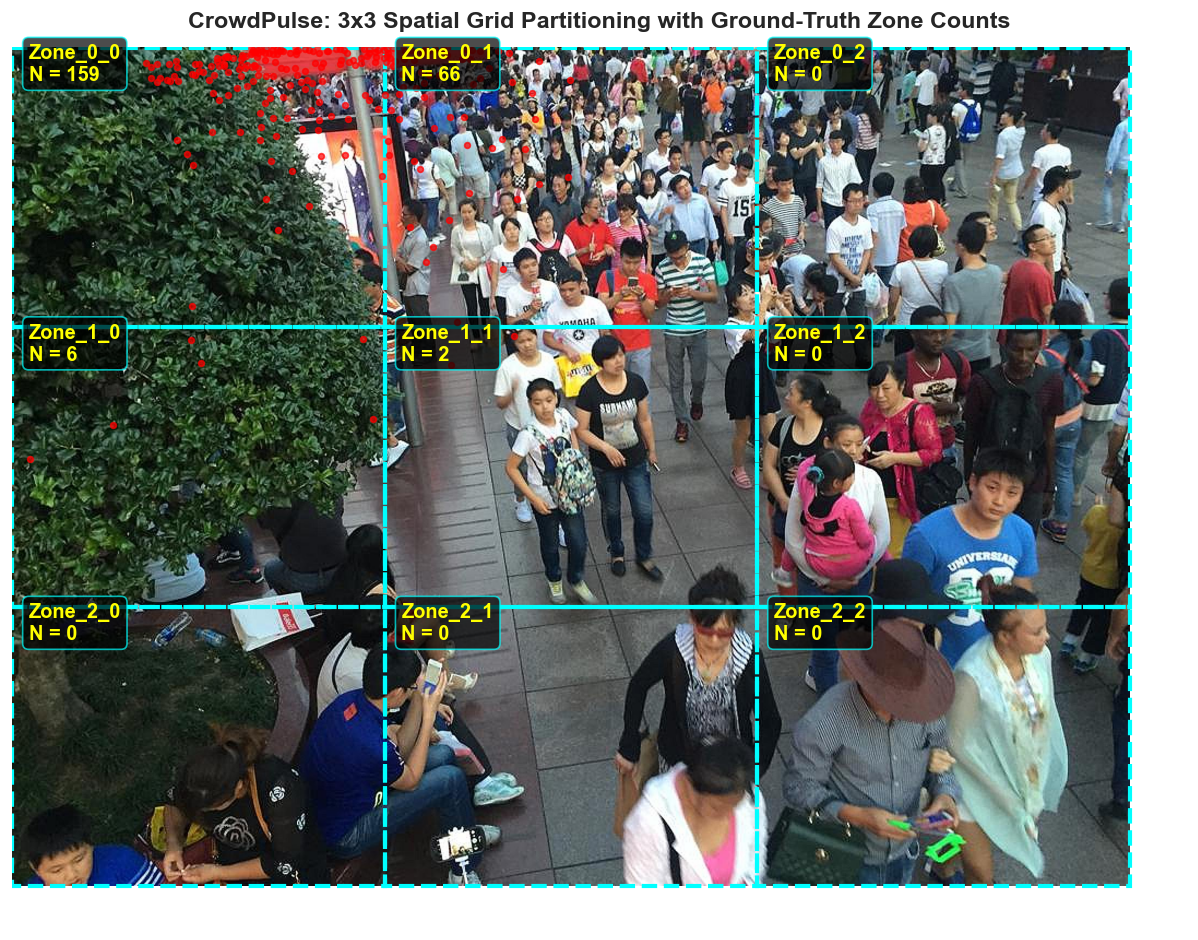

--- 3x3 Ground-Truth Zone Count Matrix ---
                Col 0 (Left)  Col 1 (Center)  Col 2 (Right)
Row 0 (Top)              159              66              0
Row 1 (Center)             6               2              0
Row 2 (Bottom)             0               0              0

Sum of Zone Counts = 233 (Matches total annotations: 233)


In [3]:
# Cell 3: Spatial Partitioning & Per-Zone Count Mapping
from src.data_loader import partition_image_into_grid, calculate_ground_truth_counts

zones = partition_image_into_grid(img, grid_size=(3, 3))
zone_counts = calculate_ground_truth_counts(head_points, grid_size=(3, 3), image_shape=(h, w))

# Visualize 3x3 Grid Partitioning on Surveillance Frame
annotated_img = img.copy()
fig, ax = plt.subplots(figsize=(12, 8), dpi=120)

for z in zones:
    ymin, xmin, ymax, xmax = z['bbox']
    r, c = z['row'], z['col']
    zid = z['zone_id']
    count = zone_counts[(r, c)]
    
    # Draw zone bounding boxes
    rect = plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, edgecolor='cyan', linewidth=2.5, linestyle='--')
    ax.add_patch(rect)
    
    # Label each zone with its ID and ground-truth count
    ax.text(xmin + 30, ymin + 60, f"{zid}\nN = {count}", color='yellow', fontsize=12, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.7, edgecolor='cyan'))

ax.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
ax.scatter(head_points[:, 0], head_points[:, 1], c='red', s=12, alpha=0.7)
ax.set_title("CrowdPulse: 3x3 Spatial Grid Partitioning with Ground-Truth Zone Counts", fontsize=14, fontweight="bold", pad=12)
ax.axis("off")
plt.tight_layout()
plt.show()

# Print Tabular Zone Summary
print("--- 3x3 Ground-Truth Zone Count Matrix ---")
grid_matrix = np.zeros((3, 3), dtype=int)
for (r, c), cnt in zone_counts.items():
    grid_matrix[r, c] = cnt
grid_df = pd.DataFrame(grid_matrix, index=["Row 0 (Top)", "Row 1 (Center)", "Row 2 (Bottom)"],
                       columns=["Col 0 (Left)", "Col 1 (Center)", "Col 2 (Right)"])
print(grid_df)
print(f"\nSum of Zone Counts = {grid_matrix.sum()} (Matches total annotations: {total_heads})")


---
## Section 4: Edge-Compatible Feature Engineering Engine

Instead of running heavy deep networks with millions of parameters, CrowdPulse extracts **31 domain-specific spatial visual descriptors** from each standardized $256 \times 256$ zone patch:

1. **Histogram of Oriented Gradients (HOG) (10 features):**
   Orientation bins capturing edge orientations of human silhouettes:
   $$\theta(x, y) = \arctan\left(\frac{I_y}{I_x}\right), \quad M(x, y) = \sqrt{I_x^2 + I_y^2}$$
   We extract 8 orientation bins across 0° to 180°, plus overall gradient mean and std.

2. **Canny Edge Density & Mean Gradient (2 features):**
   Measures the proportion of edge pixels:
   $$\text{Edge Density} = \frac{1}{|P|} \sum_{p \in P} \mathbb{I}_{\text{edge}}(p)$$
   High edge density strongly correlates with densely packed human silhouettes.

3. **Local Binary Patterns (LBP) (12 features):**
   Captures micro-texture variations (hair, clothes, pavement):
   $$LBP_{P, R} = \sum_{p=0}^{P-1} s(g_p - g_c) 2^p$$
   We extract 10 uniform pattern bins, Shannon entropy, and energy.

4. **Pixel Intensity Statistics (5 features):**
   1st and 2nd-order statistics: Mean, Standard Deviation, Variance, Skewness, Kurtosis.

5. **Normalized Spatial Coordinates (2 features):**
   Captures perspective distortion and camera elevation angle:
   $$\text{spatial\_row} = \frac{r}{\text{rows}-1}, \quad \text{spatial\_col} = \frac{c}{\text{cols}-1}$$


Training Feature Matrix: 3600 samples x 36 columns
Testing  Feature Matrix: 2844 samples x 36 columns
Number of Visual Descriptors: 31


,image_name,zone_id,head_count,canny_edge_density_ratio,hog_gradient_mean,lbp_texture_entropy,intensity_mean
0,processed_IMG_1.jpg,Zone_0_0,159,0.342041,0.351714,3.273588,69.133730
1,processed_IMG_1.jpg,Zone_0_1,66,0.321045,0.349048,3.266459,119.550290
2,processed_IMG_1.jpg,Zone_0_2,0,0.261292,0.346737,3.256968,105.022950
3,processed_IMG_1.jpg,Zone_1_0,6,0.313965,0.351788,3.266881,50.906372
4,processed_IMG_1.jpg,Zone_1_1,2,0.221069,0.342915,3.251405,103.700745


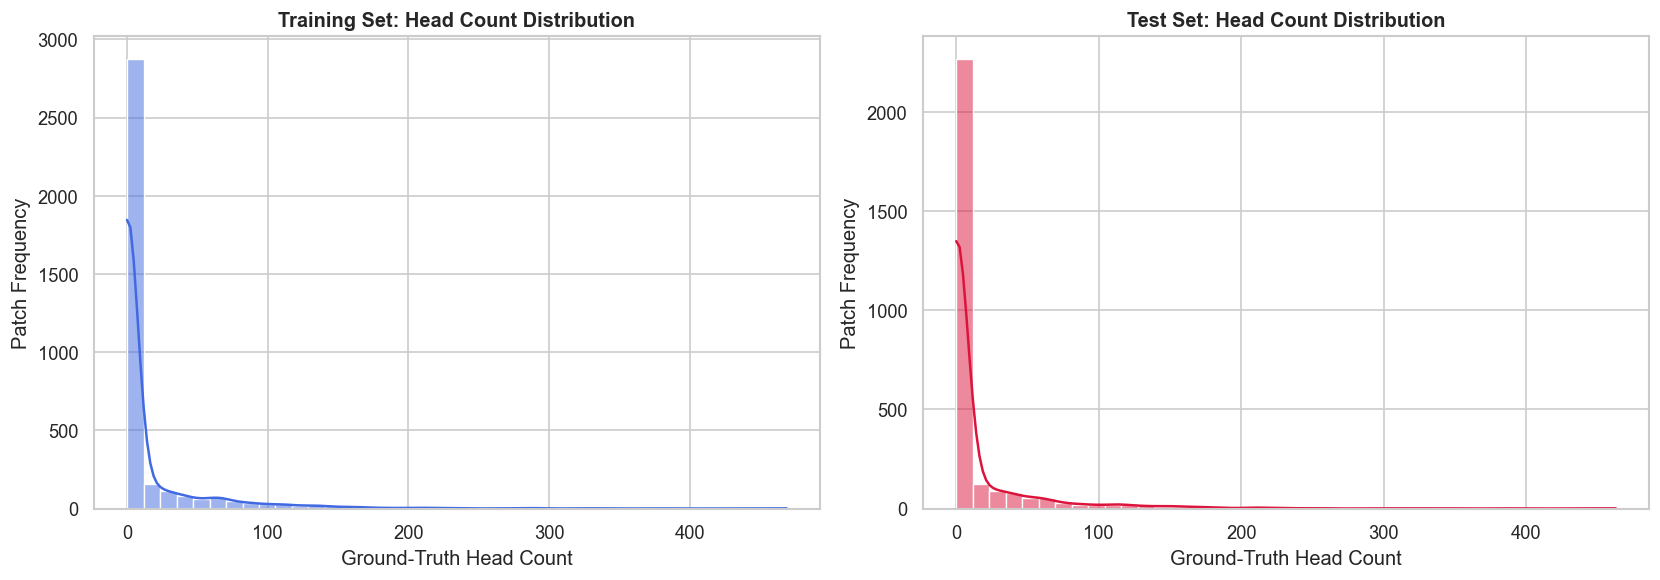

Top 5 Positively Correlated Features with Head Count:
canny_edge_density_ratio    0.411476
canny_edge_mean_gradient    0.263858
lbp_bin_5_corner_pattern    0.173949
intensity_std               0.165144
intensity_variance          0.159263
dtype: float64


In [4]:
# Cell 4: Load Tabular Features & Inspect Distributions
from src.data_loader import load_processed_data
from src.feature_extractor import FEATURE_COLUMNS

train_df, test_df = load_processed_data()

print(f"Training Feature Matrix: {train_df.shape[0]} samples x {train_df.shape[1]} columns")
print(f"Testing  Feature Matrix: {test_df.shape[0]} samples x {test_df.shape[1]} columns")
print(f"Number of Visual Descriptors: {len(FEATURE_COLUMNS)}")

# Display feature column samples
display(train_df[['image_name', 'zone_id', 'head_count', 'canny_edge_density_ratio', 'hog_gradient_mean', 'lbp_texture_entropy', 'intensity_mean']].head(5))

# Plot Target Distribution across Train and Test Sets
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)
sns.histplot(train_df['head_count'], bins=40, kde=True, ax=ax1, color='royalblue')
ax1.set_title("Training Set: Head Count Distribution", fontsize=12, fontweight="bold")
ax1.set_xlabel("Ground-Truth Head Count")
ax1.set_ylabel("Patch Frequency")

sns.histplot(test_df['head_count'], bins=40, kde=True, ax=ax2, color='crimson')
ax2.set_title("Test Set: Head Count Distribution", fontsize=12, fontweight="bold")
ax2.set_xlabel("Ground-Truth Head Count")
ax2.set_ylabel("Patch Frequency")
plt.tight_layout()
plt.show()

# Key Correlations with Head Count
corrs = train_df[FEATURE_COLUMNS].apply(lambda col: train_df['head_count'].corr(col)).sort_values(ascending=False)
print("Top 5 Positively Correlated Features with Head Count:")
print(corrs.head(5))


---
## Section 5: Model Formulation, 5-Fold Cross-Validation & Hyperparameter Tuning

We benchmark four candidate supervised regression architectures under a strict 5-fold cross-validation scheme:
1. **Ridge Regression (Baseline Linear):**
   $$\min_{w} \|y - Xw\|_2^2 + \alpha \|w\|_2^2$$
2. **Support Vector Regression (Non-Linear SVR):**
   $$\min \frac{1}{2}\|w\|^2 + C \sum (\xi_i + \xi_i^*), \quad K(x, x') = \exp(-\gamma \|x - x'\|^2)$$
3. **Random Forest Regressor (Ensemble Bagging):**
   Averaging $B$ de-correlated randomized decision trees to reduce variance.
4. **HistGradientBoostingRegressor (Ensemble Boosting):**
   Iterative gradient tree boosting with histogram binning.


--- 5-Fold Cross-Validation Benchmark Comparison ---


,Model,CV MAE (Mean),CV MAE (Std),CV RMSE (Mean),CV R2 (Mean)
3,Random Forest (Champion),6.771,0.579,20.446,0.684
2,HistGradientBoosting,7.714,0.665,20.549,0.681
1,SVR (RBF Kernel),8.789,0.735,25.456,0.522
0,Ridge Regression,17.227,0.515,28.843,0.383


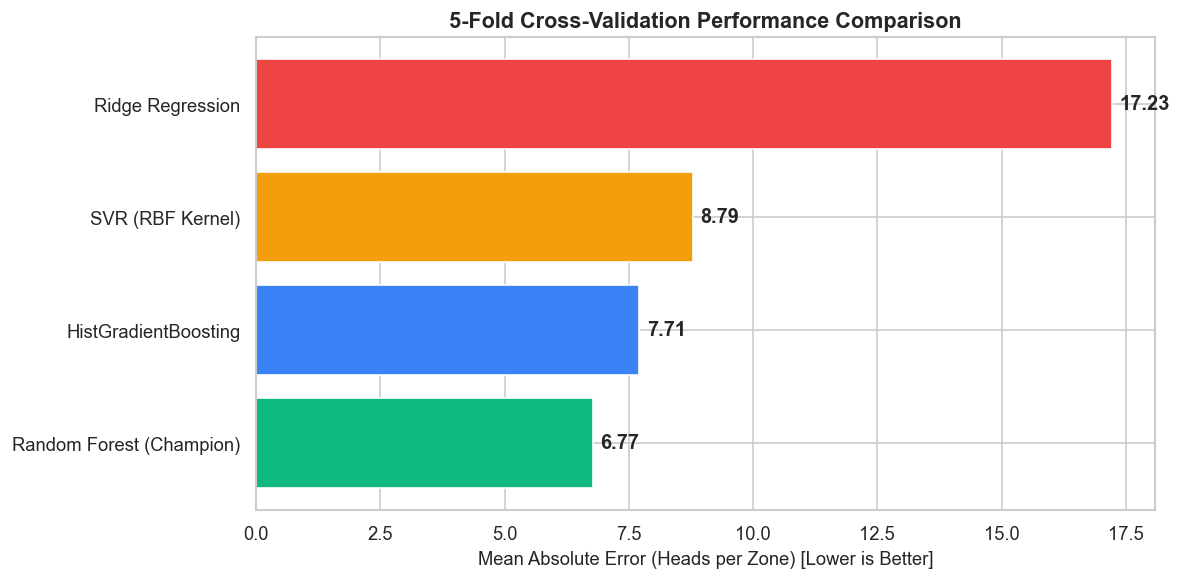

In [5]:
# Cell 5: 5-Fold Cross-Validation Benchmarking
X_train = train_df[FEATURE_COLUMNS].values
y_train = train_df['head_count'].values
X_test = test_df[FEATURE_COLUMNS].values
y_test = test_df['head_count'].values

cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Ridge Regression": Pipeline([("scaler", StandardScaler()), ("regressor", Ridge(alpha=10.0))]),
    "SVR (RBF Kernel)": Pipeline([("scaler", StandardScaler()), ("regressor", SVR(C=20.0, epsilon=1.0))]),
    "HistGradientBoosting": Pipeline([("scaler", StandardScaler()), ("regressor", HistGradientBoostingRegressor(max_iter=150, max_depth=8, learning_rate=0.08, random_state=42))]),
    "Random Forest (Champion)": Pipeline([("scaler", StandardScaler()), ("regressor", RandomForestRegressor(n_estimators=100, max_depth=14, min_samples_split=4, random_state=42, n_jobs=-1))])
}

benchmark_results = []
for name, model in models.items():
    mae_scores = -cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
    rmse_scores = -cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    r2_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="r2", n_jobs=-1)
    
    benchmark_results.append({
        "Model": name,
        "CV MAE (Mean)": mae_scores.mean(),
        "CV MAE (Std)": mae_scores.std(),
        "CV RMSE (Mean)": rmse_scores.mean(),
        "CV R2 (Mean)": r2_scores.mean(),
    })

bench_df = pd.DataFrame(benchmark_results).sort_values(by="CV MAE (Mean)")
print("--- 5-Fold Cross-Validation Benchmark Comparison ---")
display(bench_df.style.format({
    "CV MAE (Mean)": "{:.3f}",
    "CV MAE (Std)": "{:.3f}",
    "CV RMSE (Mean)": "{:.3f}",
    "CV R2 (Mean)": "{:.3f}",
}).highlight_min(subset=["CV MAE (Mean)", "CV RMSE (Mean)"], color="#c6f6d5").highlight_max(subset=["CV R2 (Mean)"], color="#c6f6d5"))

# Bar chart of MAE across models
fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
bars = ax.barh(bench_df["Model"], bench_df["CV MAE (Mean)"], color=['#10b981', '#3b82f6', '#f59e0b', '#ef4444'])
ax.set_xlabel("Mean Absolute Error (Heads per Zone) [Lower is Better]", fontsize=11)
ax.set_title("5-Fold Cross-Validation Performance Comparison", fontsize=13, fontweight="bold")
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.15, bar.get_y() + bar.get_height()/2, f"{w:.2f}", va='center', fontweight='bold')
plt.tight_layout()
plt.show()


---
## Section 6: Regression & 3-Tier Operational Risk Classification Evaluation

In operational crowd monitoring, predicting continuous count is necessary, but triggering timely safety alerts requires categorizing zones into risk tiers:
- **Green Tier ($< 10$ heads):** Free pedestrian movement; normal operations.
- **Yellow Tier ($10 - 24$ heads):** Elevated density; surveillance monitoring alert.
- **Red Tier ($\ge 25$ heads):** Critical bottleneck formation; immediate intervention required.

We evaluate both continuous regression metrics ($MAE, RMSE, R^2$) and multi-class classification performance.


Hold-Out Test MAE:  6.569 heads/zone
Hold-Out Test RMSE: 19.743 heads/zone
Hold-Out Test R2:   0.724

--- Multi-Class Operational Risk Tier Classification Report ---
              precision    recall  f1-score   support

       Green      0.996     0.983     0.989      2246
      Yellow      0.795     0.944     0.863       444
         Red      0.535     0.351     0.424       154

    accuracy                          0.942      2844
   macro avg      0.775     0.759     0.759      2844
weighted avg      0.940     0.942     0.939      2844



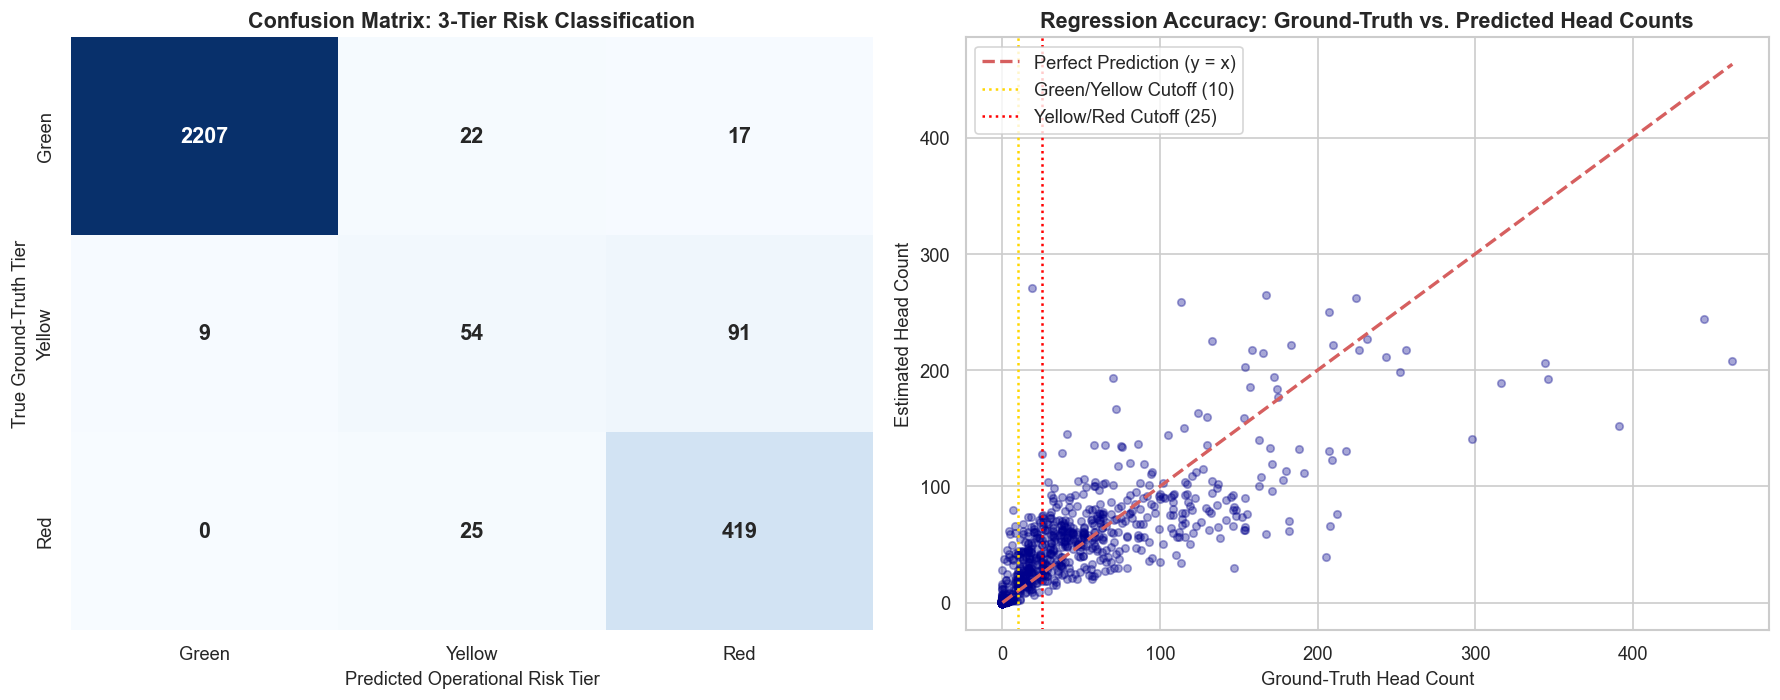

In [6]:
# Cell 6: Hold-Out Test Evaluation & Confusion Matrix
from src.evaluate import discretize_counts_to_tiers

champion_pipeline = models["Random Forest (Champion)"]
champion_pipeline.fit(X_train, y_train)

# Continuous Predictions
raw_preds = champion_pipeline.predict(X_test)
y_pred = np.clip(raw_preds, 0, None)

test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = root_mean_squared_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)

print(f"Hold-Out Test MAE:  {test_mae:.3f} heads/zone")
print(f"Hold-Out Test RMSE: {test_rmse:.3f} heads/zone")
print(f"Hold-Out Test R2:   {test_r2:.3f}")

# Categorical Risk Tier Discretization
y_test_tiers = discretize_counts_to_tiers(y_test, green_cutoff=10.0, red_cutoff=25.0)
y_pred_tiers = discretize_counts_to_tiers(y_pred, green_cutoff=10.0, red_cutoff=25.0)
tier_labels = ["Green", "Yellow", "Red"]

print("\n--- Multi-Class Operational Risk Tier Classification Report ---")
print(classification_report(y_test_tiers, y_pred_tiers, target_names=tier_labels, digits=3))

# Render Confusion Matrix
cm = confusion_matrix(y_test_tiers, y_pred_tiers, labels=tier_labels)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=120)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=tier_labels, yticklabels=tier_labels, ax=ax1,
            cbar=False, annot_kws={"size": 13, "weight": "bold"})
ax1.set_title("Confusion Matrix: 3-Tier Risk Classification", fontsize=13, fontweight="bold")
ax1.set_xlabel("Predicted Operational Risk Tier", fontsize=11)
ax1.set_ylabel("True Ground-Truth Tier", fontsize=11)

# True vs. Predicted Scatter
ax2.scatter(y_test, y_pred, alpha=0.35, color='darkblue', s=20)
ax2.plot([0, max(y_test)], [0, max(y_test)], 'r--', linewidth=2, label='Perfect Prediction (y = x)')
ax2.axvline(10, color='gold', linestyle=':', label='Green/Yellow Cutoff (10)')
ax2.axvline(25, color='red', linestyle=':', label='Yellow/Red Cutoff (25)')
ax2.set_title("Regression Accuracy: Ground-Truth vs. Predicted Head Counts", fontsize=13, fontweight="bold")
ax2.set_xlabel("Ground-Truth Head Count", fontsize=11)
ax2.set_ylabel("Estimated Head Count", fontsize=11)
ax2.legend(loc="upper left")
plt.tight_layout()
plt.show()


---
## Section 7: Explainable AI with SHAP (TreeExplainer)

Safety-critical applications cannot be black boxes. We employ **SHAP (SHapley Additive exPlanations)** based on cooperative game theory to quantify the exact contribution $\\phi_i$ of each feature to the model's estimate:
$$\\phi_i = \\sum_{S \\subseteq F \\setminus \\{i\\}} \\frac{|S|!(|F| - |S| - 1)!}{|F|!} \\left[f_x(S \\cup \\{i\\}) - f_x(S)\\right]$$

We visualize:
1. **Global Summary Beeswarm:** Ranking of all 31 features by overall impact across the dataset.
2. **Local Waterfall Explanation:** Breakdown of a high-density bottleneck zone showing the exact visual evidence that pushed the count into the Red tier.


C:\Users\pudis\AppData\Local\Temp\ipykernel_17652\1857292537.py:16: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values.values, features=X_sample, feature_names=FEATURE_COLUMNS, max_display=12, show=False)


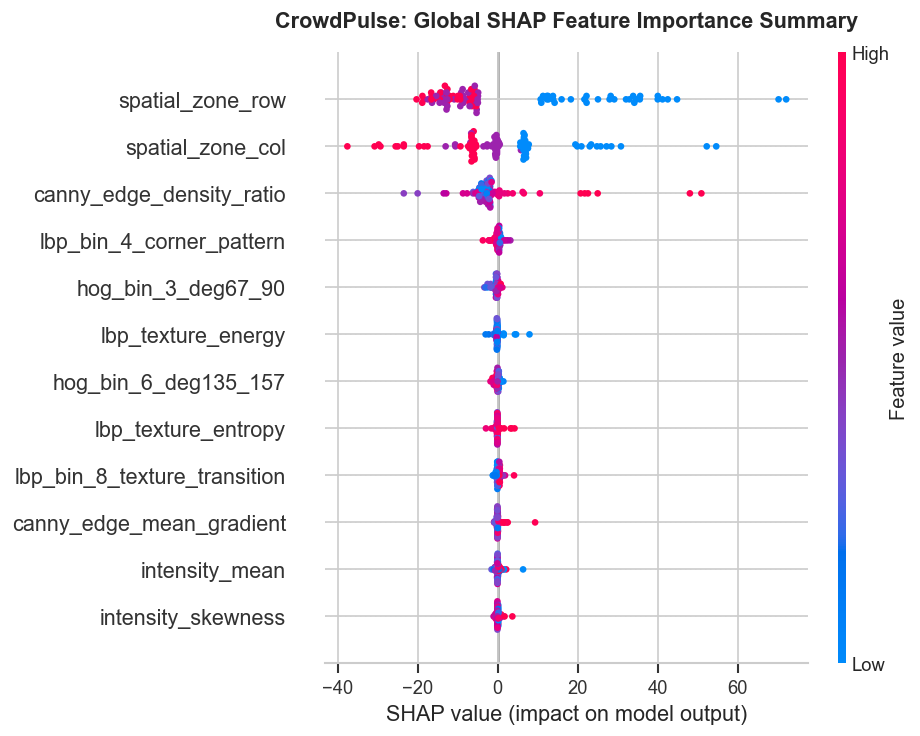

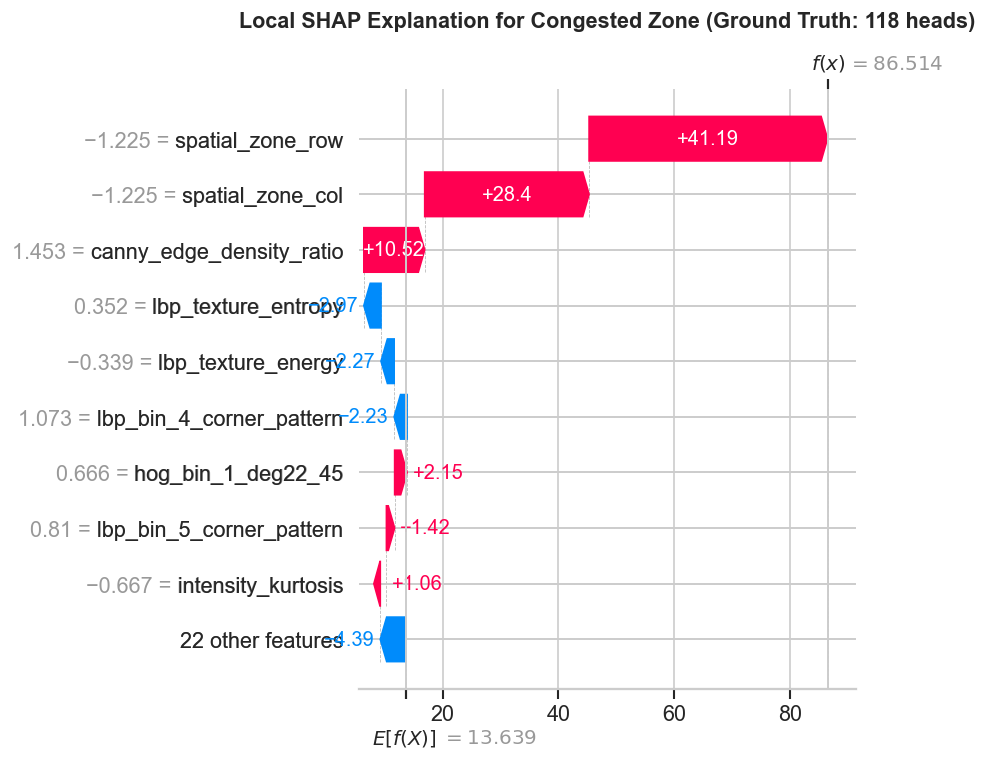

In [7]:
# Cell 7: Global Beeswarm & Local Waterfall Explanations
rf_regressor = champion_pipeline.named_steps['regressor']
scaler = champion_pipeline.named_steps['scaler']

explainer = shap.TreeExplainer(rf_regressor)

# Transform sample test features
X_sample = X_test[:100]
X_sample_scaled = scaler.transform(X_sample)

shap_values = explainer(X_sample_scaled)
shap_values.feature_names = FEATURE_COLUMNS

# 1. Global Summary Beeswarm Plot
plt.figure(figsize=(10, 7), dpi=120)
shap.summary_plot(shap_values.values, features=X_sample, feature_names=FEATURE_COLUMNS, max_display=12, show=False)
plt.title("CrowdPulse: Global SHAP Feature Importance Summary", fontsize=13, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

# 2. Find a congested sample in Red tier (>=25) for local waterfall explanation
congested_indices = np.where(y_test[:100] >= 25)[0]
sample_idx = int(congested_indices[0]) if len(congested_indices) > 0 else 0

plt.figure(figsize=(9, 5.5), dpi=120)
shap.plots.waterfall(shap_values[sample_idx], max_display=10, show=False)
plt.title(f"Local SHAP Explanation for Congested Zone (Ground Truth: {y_test[sample_idx]:.0f} heads)", fontsize=13, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()


---
## Section 8: Model Serialization & Decentralized Multi-Agent Coordination

Finally, we serialize the champion pipeline to `models/crowdpulse_pipeline.joblib` and demonstrate the decentralized **Multi-Agent Coordination Broker**:
- Each zone is an autonomous `ZoneAgent`.
- The `AgentCoordinator` maintains an adjacency topology.
- When two adjacent zones reach the **Red Tier** simultaneously, the system triggers a **CRITICAL COORDINATED BOTTLENECK ALERT** and generates dynamic rerouting instructions to guide crowd flow toward neighboring safe zones.


In [8]:
# Cell 8: Model Serialization & Multi-Agent Coordination Broker
from src.agent_coordinator import AgentCoordinator

# 1. Serialize champion pipeline to disk
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)
model_path = models_dir / "crowdpulse_pipeline.joblib"
joblib.dump(champion_pipeline, model_path)
print(f"Champion Pipeline serialized successfully to: {model_path}")

# 2. Simulate Multi-Agent System on a High-Density Surveillance Frame
coord = AgentCoordinator(grid_size=(3, 3), allow_diagonal_adjacency=True, green_cutoff=10.0, red_cutoff=25.0)

# Simulate scenario: Zone_0_0 and Zone_0_1 experience rapid influx
simulated_counts = {
    "Zone_0_0": 34.0,  # Red
    "Zone_0_1": 29.0,  # Red (Adjacent to 0_0!)
    "Zone_0_2": 8.0,   # Green
    "Zone_1_0": 6.0,   # Green
    "Zone_1_1": 14.0,  # Yellow
    "Zone_1_2": 5.0,   # Green
    "Zone_2_0": 3.0,   # Green
    "Zone_2_1": 4.0,   # Green
    "Zone_2_2": 2.0,   # Green
}

coord.update_zone_counts(simulated_counts)
system_state = coord.evaluate_system_state()

print("\n=============================================================")
print("MULTI-AGENT COORDINATION TELEMETRY REPORT")
print("=============================================================")
print(f"System Operational Status: {system_state['system_status']}")
print(f"Total Estimated Influx:   {system_state['total_estimated_count']} pedestrians")
print(f"Critical Bottleneck Zones: {system_state['red_zones']}")
print(f"Adjacent Red Zone Pairs:   {system_state['adjacent_red_pairs']}")
print("\nDynamic Rerouting Directives:")
for directive in system_state['rerouting_directives']:
    print(f"  [DISPATCH] {directive}")

print("\nRecent Inter-Agent Message Log:")
log_df = pd.DataFrame(coord.message_log[-5:])
display(log_df[['timestamp', 'sender', 'recipient', 'level', 'message']])
print("=============================================================")
print("CrowdPulse Academic Pipeline Execution Completed Successfully.")


Champion Pipeline serialized successfully to: D:\studies\LPU\sem_3\INT395 - Supervised Learning\CrowdPulse\models\crowdpulse_pipeline.joblib

MULTI-AGENT COORDINATION TELEMETRY REPORT
System Operational Status: CRITICAL COORDINATED BOTTLENECK ALERT
Total Estimated Influx:   105.0 pedestrians
Critical Bottleneck Zones: ['Zone_0_0', 'Zone_0_1']
Adjacent Red Zone Pairs:   [('Zone_0_0', 'Zone_0_1')]

Dynamic Rerouting Directives:
  [DISPATCH] Divert pedestrian influx from Zone_0_0 & Zone_0_1 towards relief corridor Zone_1_2 (Occupancy: 5.0).

Recent Inter-Agent Message Log:


,timestamp,sender,recipient,level,message
0,16:52:34.066,Zone_0_0,Coordinator,WARNING,Status transition: Green -> Red (count: 34.0)
1,16:52:34.066,Zone_0_1,Coordinator,WARNING,Status transition: Green -> Red (count: 29.0)
2,16:52:34.066,Zone_1_1,Coordinator,WARNING,Status transition: Green -> Yellow (count: 14.0)
3,16:52:34.066,Coordinator,BROADCAST,CRITICAL,CRITICAL BOTTLENECK DETECTED! Adjacent congest...
4,16:52:34.066,Coordinator,"Zone_0_0,Zone_0_1",CRITICAL,DIRECTIVE: Divert pedestrian influx from Zone_...


CrowdPulse Academic Pipeline Execution Completed Successfully.
